## Анализ клиентской базы: EDA и проверка гипотез о покупательском поведении

### Подготовка данных

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
customers = pd.read_csv("Mall_Customers.csv")
customers

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


### Первичный анализ датасета и постановка гипотез

Источник датасета: открытый набор "Mall Customers"

Объем выборки: 200 клиентов

Описание признаков:

CustomerID — идентификатор

Gender — пол (категориальный, бинарный)

Age — возраст (количественный, 18–70 лет)

Annual_income — годовой доход в тыс. $ (количественный, 15–137)

Spending_score — индекс потребительской активности 1–100 (целевая метрика)

Изучим описательные статистики датасета.

In [48]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


Количество переменных - 5

Количество наблюдений - 200

Тип переменных - int64


Заменим названия признаков и проверим данные на наличие пустых наблюдений и дубликатов.

In [49]:
customers.isna().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [50]:
duplicates_count = customers.duplicated().sum()
print(f"Количество дублирующихся строк: {duplicates_count}")

Количество дублирующихся строк: 0


Дубликаты и пропуски не обнаружены.

Проанализируем характеристики датасета.

In [51]:
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Средний возраст покупателя - 38,85

У индекса потребления покупателя наблюдается разброс значений 1-99

У порядка 75% покупателей доход ниже 78k$

Максимальный возраст покупателя? - 70 лет

Переименуем признаки.

In [52]:
customers_renamed = customers.rename(columns={'Annual Income (k$)': 'Annual_income', 'Spending Score (1-100)': 'Spending_score', 'Genre':'Gender'})
customers_renamed

,CustomerID,Gender,Age,Annual_income,Spending_score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [53]:
customers_renamed['Gender'] = customers_renamed['Gender'].apply(lambda x: 0 if x=='Male' else 1) # представим переменную пол в булевом виде
customers_renamed.head()

,CustomerID,Gender,Age,Annual_income,Spending_score
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


Перед началом анализа выдвинем три продуктовые гипотезы:
1. H1: Существует отрицательная корреляция между возрастом и индексом расходов (молодая аудитория склонна тратить больше).
2. H2: Годовой доход положительно коррелирует с индексом расходов (чем выше доход, тем выше траты).
3. H3: Гендерная принадлежность значимо влияет на паттерны расходов (мужчины и женщины тратят по-разному при одинаковом доходе).


### Проверка гипотез

Сначала проанализируем демографическое распределение покупателей с помощью гистограммы.

,count
Gender,
1,112
0,88


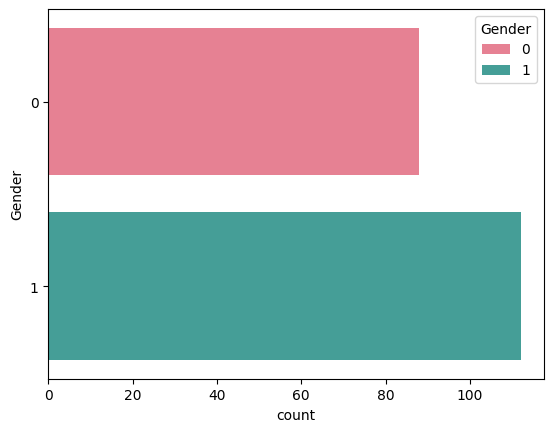

In [54]:
sns.countplot(y = 'Gender', data = customers_renamed, palette="husl", hue = "Gender")
customers_renamed["Gender"].value_counts()

В выборке 88 мужчин и 112 женщин, распределение пола достаточно сбалансировано, что позволяет проводить сравнительный анализ.

Построим функции плотности для трех переменных: пол, доход, индекс потребления.

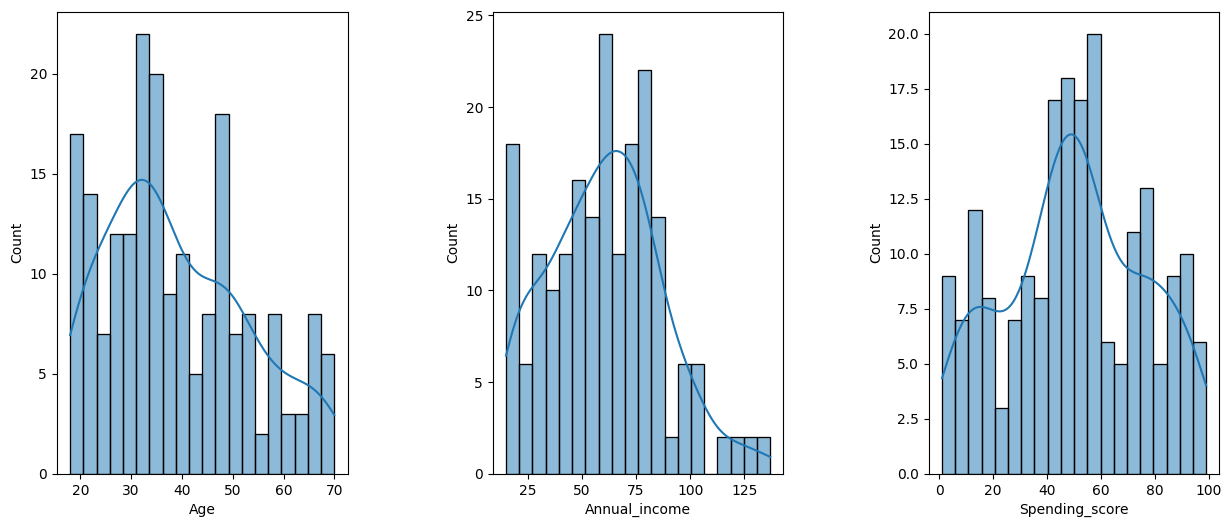

In [55]:
plt.figure(1 , figsize = (15 , 6))
feature_list = ['Age','Annual_income', "Spending_score"]
pos = 1
for i in feature_list:
    plt.subplot(1 , 3 , pos)
    plt.subplots_adjust(hspace = 0.5 , wspace = 0.5)
    sns.histplot(customers_renamed[i], bins=20, kde = True)
    pos = pos + 1
plt.show()

1. Возраст (`Age`): распределение близко к нормальному, средняя возрастная группа клиентов - 30-45 лет
2. Годовой доход (`Annual_income`): наблюдается выброс в области 100-150k$, что указывает на возможное наличие VIP-клиентов
3. Индекс расходов (`Spending_score`): бимодальное распределение с "тяжелыми хвостами" - клиенты делятся на две группы: более экономные (score 1-30) и более активные покупатели (score 70-100)


Изучим попарные связи между переменными, разделяя выборки по полу.

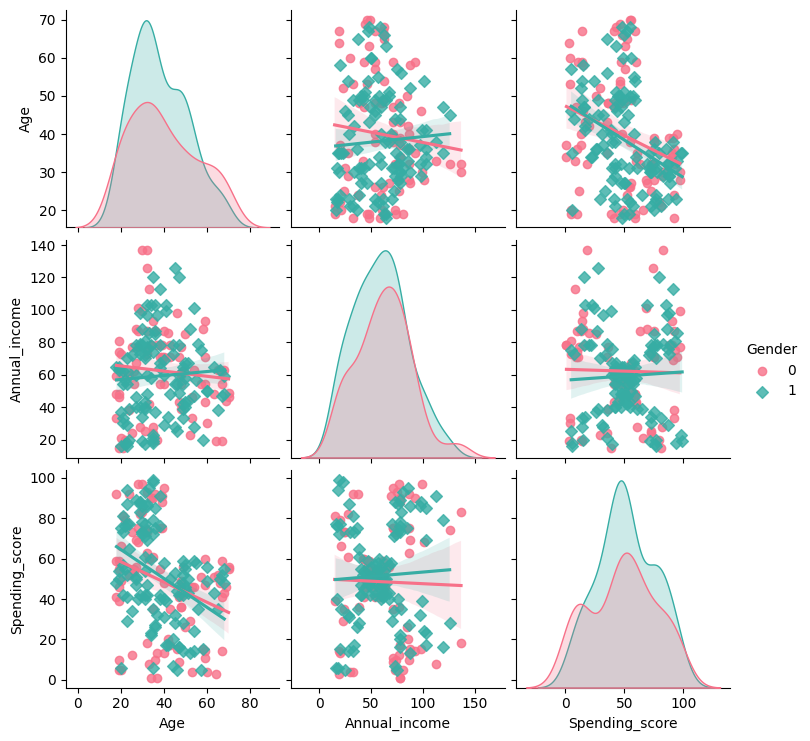

In [56]:
sns.pairplot(customers_renamed, vars=["Age", "Annual_income", "Spending_score"],  kind ="reg", hue = "Gender", palette="husl", markers = ['o','D'])

1. Возраст и доход: слабая положительная корреляция - с возрастом доход покупателя имеет тенденцию к росту
2. Доход и индекс расходов: отрицательная корреляция - клиенты с высоким доходом не обязательно тратят больше денег
3. Пол не оказывает значимого влияния на взаимосвязи между переменными - паттерны для мужчин и женщин очень похожи

Изучим попарные связи более детально.


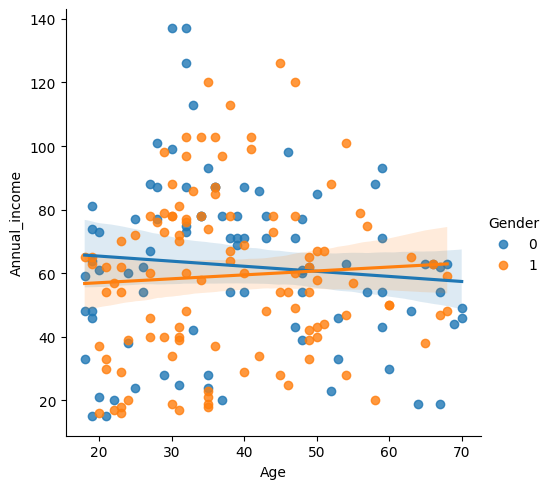

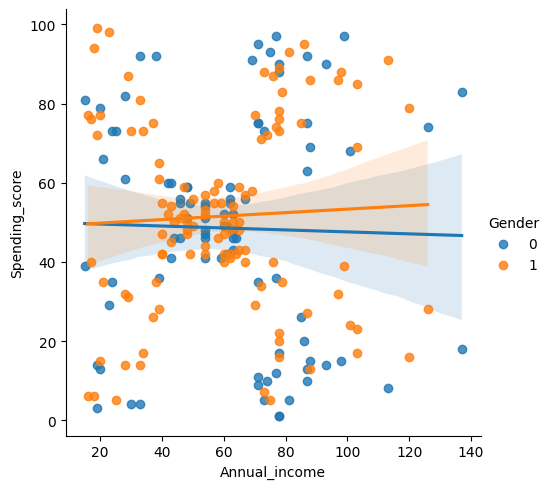

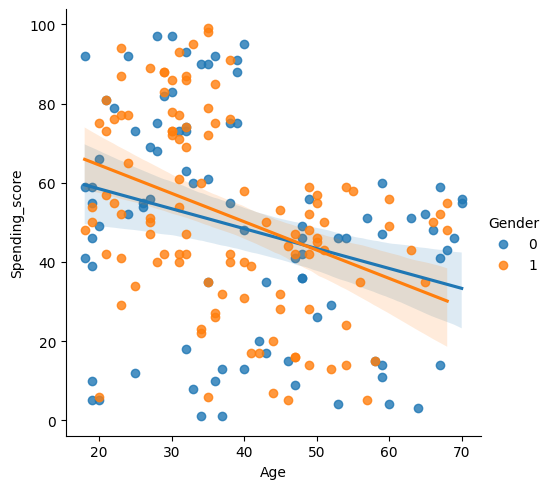

In [57]:
sns.lmplot(x = "Age", y = "Annual_income", data = customers_renamed, hue = "Gender")
sns.lmplot(x = "Annual_income", y = "Spending_score", data = customers_renamed, hue = "Gender")
sns.lmplot(x = "Age", y = "Spending_score", data = customers_renamed, hue = "Gender")


1. Заметна слабая отрицательная корреляция между возрастом и индексом расходов Spending Score: с увеличением возраста склонность к высоким тратам имеет тенденцию к снижению.

2. При этом визуальный анализ кластеров не позволяет выявить статистически значимого влияния пола на взаимосвязи «доход-возраст» и «доход-расходы»: паттерны поведения мужчин и женщин практически полностью перекрываются. Это подтверждает универсальность поведенческих моделей для обеих групп и позволяет рекомендовать единые стратегии таргетирования.

### Вывод
H1: Подтверждена частично. Выявлена слабая отрицательная корреляция: с увеличением возраста индекс расходов имеет общую тенденцию к снижению, но разброс значений очень велик.

H2: Опровергнута. Высокий годовой доход не гарантирует высокий индекс расходов. На графике `Income vs Spending` виден вертикальный кластер клиентов с доходом >100k$, которые при этом имеют минимальный индекс трат (1-20).

H3: Опровергнута. Визуальный анализ регрессионных моделей (`lmplot`) показал практически полное перекрытие облаков точек и линий тренда для мужчин и женщин. Пол не является значимым фактором.

Можно сказать, что опираться на пол или возраст при сегментации этой аудитории неэффективно. Гораздо важнее поведенческие метрики (история трат).
Индекс расходов имеет два явных пика (1-30 и 70-100). Крроме того, возможно, для клиентов с высоким доходом, но низким Spending Score нужны триггеры на рациональность и выгоду. А для кластера с высоким Spending Score — триггеры на эмоции и новизну.